In this notebook we demonstrate the performance of a U-Net machine learning model in predicting eddy kinetic energy.

The model is one of the released U-Nets (run `20260928-145859`). It was trained on four Southern Ocean regions of the DINO configuration with three input features: coarse kinetic energy (`coarse_ke`), relative vorticity over the Coriolis parameter (`vor`) and deformation radius over grid scale (`sa`). The sample data are ten days of the `SO_JET` region, taken from the part of the data the model was not trained on.

Process:<br/>
    1) Load in a small sample of test data from a single region,<br/>
    2) Predict Eddy Kinetic Energy, <br/>
    3) Present some brief evaluation metrics,<br/>
    4) Read the training record stored with the model.

In [1]:
import warnings
warnings.filterwarnings('ignore')  # Suppress all warnings
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # Suppress TensorFlow logging

from ml_model_ai4pex.model_setup import setup_scenario, \
      get_data, get_data_split
from ml_model_ai4pex.predict_model import predict_model

from matplotlib import pyplot as plt
import cmocean
import numpy as np
from skimage.metrics import structural_similarity as ssim
from sklearn.metrics import r2_score
import logging
import argparse
import keras


### Functions

In [2]:
def compute_scores(ds):

    r2 = np.zeros(ds.time_counter.size)
    ssim_pred = np.zeros(ds.time_counter.size)

    for i in range(ds.time_counter.size):

        r2[i] = r2_score(ds.fine_ke_true.isel(time_counter=i, var=0).to_numpy().flatten(), 
                    ds.fine_ke_pred.isel(time_counter=i, var=0).to_numpy().flatten())

        # now ssim score
        ssim_pred[i] = ssim(ds.fine_ke_true.isel(time_counter=i, var=0).to_numpy(), 
                    ds.fine_ke_pred.isel(time_counter=i, var=0).to_numpy(),
                    data_range = ds.fine_ke_pred.isel(time_counter=i, var=0).max().values-\
                            ds.fine_ke_pred.isel(time_counter=i, var=0).min().values,
                    )
        
    return r2, ssim_pred

### Setup
Create a null logger and define the arguments needed to run the UNet model.

In [3]:
# Null logger — discards all output
logger = logging.getLogger("notebook")
logger.handlers.clear()
logger.addHandler(logging.NullHandler())
logger.propagate = False

# Arguments for UNet prediction
args = argparse.Namespace(
    # Model architecture
    model="unet",
    features=["coarse_ke", "vor", "sa"],  # in the order the model was trained with
    target=["fine_ke"],
    base_filters=64,
    depth=2,
    # Data paths
    data_dir="./sample_dataset_for_github/",
    data_filenames=[
        "sample_vor_{domain}.nc",
        "sample_eke_{domain}.nc",
        "sample_mke_{domain}.nc",
        "sample_sa_{domain}.nc",
        "mask_{domain}.nc",
    ],
    domain=["SO_JET"],
    # Model path
    model_dir="./sample_model/",
    model_filename="sample_model.keras",
    # Data split
    train=False,
    predict=True,
    train_ratio=0.1,
    val_ratio=0.1,
    test_ratio=0.8,
    train_stride=1,
    shuffle_seed=42,
    # Normalisation: the statistics the model was trained with (also in its training record)
    local_norm=True,
    norm_stats={
        "coarse_ke_log": {"mean": -3.238,  "std": 1.6998},
        "vor":           {"mean": -0.0025, "std": 0.1423},
        "sa":            {"mean": 0.604,   "std": 0.206},
    },
    # Prediction output
    predict_save_filename=None,
    predict_save_dir=None,
    # Misc
    verbose=False,
)

### Setup scenario

In [4]:
scenario = setup_scenario(args, logger)
scenario

Scenario(input_var=['coarse_ke', 'vor', 'sa'], target=['fine_ke'], filters=None, kernels=None, padding=None, dilation_rates=None, name=None, base_filters=64, depth=2)

### Load data

In [5]:
ds, sc = get_data(scenario, args, logger)
ds, sc

Scenario(input_var=['coarse_ke', 'vor', 'sa'], target=['fine_ke'], filters=None, kernels=None, padding=None, dilation_rates=None, name=None, base_filters=64, depth=2)
Scenario(input_var=['coarse_ke', 'vor', 'sa'], target=['fine_ke'], filters=None, kernels=None, padding=None, dilation_rates=None, name=None, base_filters=64, depth=2)


(<xarray.Dataset> Size: 794kB
 Dimensions:        (r: 1, y_c: 40, x_c: 40, t: 10)
 Coordinates:
     y_c            (r, y_c) int64 320B 7 8 9 10 11 12 13 ... 41 42 43 44 45 46
     x_c            (r, x_c) int64 320B 3 4 5 6 7 8 9 10 ... 36 37 38 39 40 41 42
     glamt          (r, y_c, x_c) float64 13kB 3.375 3.625 3.875 ... 12.88 13.12
     gphit          (r, y_c, x_c) float64 13kB -46.22 -46.22 ... -39.07 -39.07
   * t              (t) object 80B 0072-02-12 00:00:00 ... 0072-02-21 00:00:00
     nav_lev        (r) float32 4B 5.034
 Dimensions without coordinates: r
 Data variables:
     vor            (r, y_c, x_c, t) float64 128kB -0.3564 -0.5772 ... -0.04383
     fine_ke        (r, t, y_c, x_c) float64 128kB 0.0018 0.003476 ... 0.0004313
     coarse_ke      (r, t, y_c, x_c) float64 128kB 0.07992 0.07358 ... 0.003074
     sa             (r, t, y_c, x_c) float64 128kB -1.842 -1.811 ... 0.5716
     coarse_ke_log  (r, t, y_c, x_c) float64 128kB 0.4184 0.3698 ... -1.498
     fine_ke_log 

### Split data
Split into validation and test sets. Since `args.train=False`, `get_data_split` returns `(ds_val, ds_test)`.

In [6]:
ds_val, ds_test = get_data_split(ds, args, logger)
ds_test

<xarray.Dataset> Size: 641kB
Dimensions:        (r: 1, y_c: 40, x_c: 40, t: 8)
Coordinates:
    y_c            (r, y_c) int64 320B 7 8 9 10 11 12 13 ... 41 42 43 44 45 46
    x_c            (r, x_c) int64 320B 3 4 5 6 7 8 9 10 ... 36 37 38 39 40 41 42
    glamt          (r, y_c, x_c) float64 13kB 3.375 3.625 3.875 ... 12.88 13.12
    gphit          (r, y_c, x_c) float64 13kB -46.22 -46.22 ... -39.07 -39.07
  * t              (t) object 64B 0072-02-14 00:00:00 ... 0072-02-21 00:00:00
    nav_lev        (r) float32 4B 5.034
Dimensions without coordinates: r
Data variables:
    vor            (r, y_c, x_c, t) float64 102kB -0.8662 -1.15 ... -0.04383
    fine_ke        (r, t, y_c, x_c) float64 102kB 0.002799 ... 0.0004313
    coarse_ke      (r, t, y_c, x_c) float64 102kB 0.1143 0.04879 ... 0.003074
    sa             (r, t, y_c, x_c) float64 102kB -1.809 -1.751 ... 0.5716
    coarse_ke_log  (r, t, y_c, x_c) float64 102kB 0.6289 0.1281 ... -1.498
    fine_ke_log    (r, t, y_c, x_c) float64 102kB -5.878 -4.777 ... -7.749

### Predict EKE
Load the trained UNet model and generate predictions on the test set.

In [7]:
pred_ds = predict_model(sc, ds_test, args, logger)
pred_ds

Input shape: (None, 40, 40, 3)


Input shape: (8, 40, 40, 3)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 461ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 487ms/step


I0000 00:00:1791975178.088270 1138209 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


<xarray.Dataset> Size: 179kB
Dimensions:       (time_counter: 8, y: 40, x: 40, var: 1)
Coordinates:
  * time_counter  (time_counter) object 64B 0072-02-14 00:00:00 ... 0072-02-2...
    gphit         (y, x) float64 13kB -46.22 -46.22 -46.22 ... -39.07 -39.07
    glamt         (y, x) float64 13kB 3.375 3.625 3.875 ... 12.62 12.88 13.12
  * var           (var) <U11 44B 'fine_ke_log'
Dimensions without coordinates: y, x
Data variables:
    fine_ke_pred  (time_counter, y, x, var) float32 51kB 0.008925 ... 0.000509
    fine_ke_true  (time_counter, y, x, var) float64 102kB 0.002799 ... 0.0004313
Attributes:
    Title:        Fine kinetic energy - predicted and truth
    Description:  Predicted fine kinetic energy from coarse-grained data usin...
    Units:        ['m$^2$/s$^2$']
    Source:       ./sample_model/sample_model.keras

### Evaluation in a Southern Ocean boundary current region

1) Plot EKE and difference,
2) Plot R2 and SSIM scores.

#### Plot EKE at instantaneous snapshot

Text(0.5, 1.0, 'EKE Difference (Pred - True)')

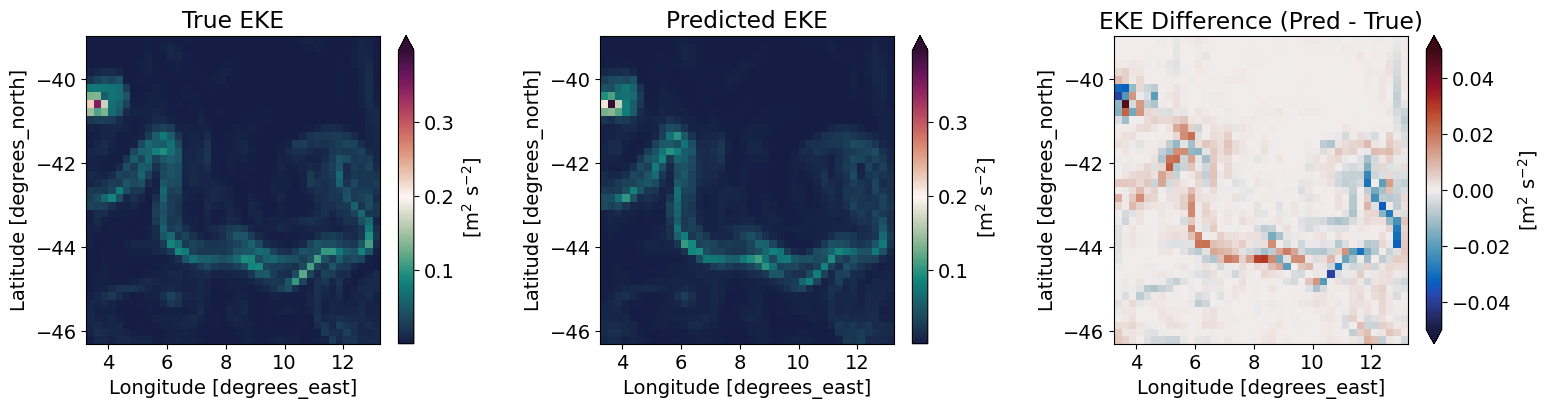

In [8]:
plt.rcParams.update({'font.size': 14})
fig = plt.figure(figsize=(18, 4))
gs = fig.add_gridspec(1, 3, wspace=0.4)
axs = gs.subplots()

vmin_eke = min(pred_ds.fine_ke_true.min().values, pred_ds.fine_ke_pred.min().values)
vmax_eke = max(pred_ds.fine_ke_true.max().values, pred_ds.fine_ke_pred.max().values)

pred_ds.fine_ke_true.isel(time_counter=0).plot(
    ax=axs[0],
    vmin=vmin_eke, vmax=vmax_eke,
    x='glamt', y='gphit',
    cmap=cmocean.cm.curl,
    cbar_kwargs={'label': '[m$^2$ s$^{-2}$]'},
    extend='max')
axs[0].set_title('True EKE')

pred_ds.fine_ke_pred.isel(time_counter=0).plot(
    ax=axs[1],
    vmin=vmin_eke, vmax=vmax_eke,
    x='glamt', y='gphit',
    cmap=cmocean.cm.curl,
    cbar_kwargs={'label': '[m$^2$ s$^{-2}$]'},
    extend='max')
axs[1].set_title('Predicted EKE')
axs[1].set_xlabel('Longitude [degrees_east]')
axs[1].set_ylabel('Latitude [degrees_north]')

diff = pred_ds.fine_ke_pred.isel(time_counter=0) - pred_ds.fine_ke_true.isel(time_counter=0)

diff.plot(
    ax=axs[2],
    vmin=-0.05, vmax=0.05,
    x='glamt', y='gphit',
    cmap=cmocean.cm.balance,
    cbar_kwargs={'label': '[m$^2$ s$^{-2}$]'},
    extend='both')
axs[2].set_title('EKE Difference (Pred - True)')

#### Plot R2 and SSIM score

On a small sample set of 8 timesteps, the unet model can predict a large proportion of the variance, given by the high R2 score. The high SSIM score shows true and predicted EKE fields are structurally similar.

In [9]:
r21, ssim1 = compute_scores(pred_ds)

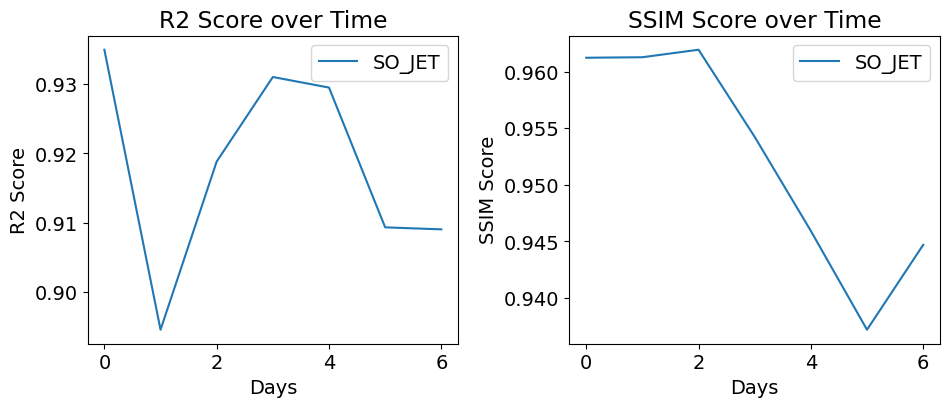

In [10]:
fig = plt.figure(figsize=(11, 4))
gs = fig.add_gridspec(1, 2, wspace=0.3)
axs = gs.subplots()

axs[0].plot(r21[:-1], label='SO_JET')
axs[0].set_title('R2 Score over Time')
axs[0].set_xlabel('Days')
axs[0].set_ylabel('R2 Score')
axs[0].legend()


axs[1].plot(ssim1[:-1], label='SO_JET')
axs[1].set_title('SSIM Score over Time')
axs[1].set_xlabel('Days')
axs[1].set_ylabel('SSIM Score')
axs[1].legend()

plt.tight_layout()

### Training record
A model trained with `run/run_model.py` carries a record of its training run, which loads as `model.provenance`. Three fields (the model directory, the host name and the SLURM job ID) were removed from the sample model's copy.

In [11]:
model = keras.saving.load_model(args.model_dir + args.model_filename)
record = model.provenance

print("run ID:         ", record["run_id"])
print("regions:        ", record["run_settings"]["domain"])
print("features:       ", record["run_settings"]["features"])
print("normalisation:  ", record["normalisation"]["stats"])
print("data split:     ", record["data_split"])
print("epochs:         ", record["training_history"]["epochs_completed"],
      "(weights from epoch", str(record["training_history"]["weights_from_epoch"]) + ")")
print("environment:    ", record["environment"])

Input shape: (None, 40, 40, 3)


run ID:          20260928-145859
regions:         ['SO_JET', 'SO_EAST', 'SO_GYRE', 'SO_TROP']
features:        ['coarse_ke_log', 'vor', 'sa']
normalisation:   {'vor': {'mean': -0.0025, 'std': 0.1423}, 'coarse_ke_log': {'mean': -3.238, 'std': 1.6998}, 'sa': {'mean': 0.604, 'std': 0.206}}
data split:      {'train_ratio': 0.83, 'val_ratio': 0.085, 'test_ratio': 0.085, 'train_stride': 5, 'shuffle_seed': 41, 'train_omit_months': None, 'n_train_samples': 2872, 'n_val_samples': 1468}
epochs:          47 (weights from epoch 37)
environment:     {'python': '3.9.25', 'tensorflow': '2.20.0', 'keras': '3.10.0', 'numpy': '2.0.2', 'xarray': '2024.7.0', 'gpus': ['NVIDIA A100-SXM4-40GB']}
